
# Phase 11A — Separate Learning of Dissipative and Rotational Latent Dynamics

## Why this phase now?

Phase 10D gives enough evidence to justify moving from diagnostics to a controlled architectural experiment:

- two queries are non-degenerate in 100% of bootstrap draws;
- higher-order Walsh energy remains nonzero under resampling;
- some one-bit effects have stable sign;
- the noise-corrected Laplacian energy remains positive for the informative queries.

The third sparse query remains exploratory, so **Phase 11A is deliberately synthetic and controlled**.

The goal is to test whether a structured latent vector field can separately learn:

\[
F_{\rm diss}(z)
=
-M_\theta\nabla U_\theta(z)
\]

and

\[
F_{\rm rot}(z)
=
A_\theta\nabla H_\theta(z),
\]

with

\[
M_\theta=M_\theta^\top\succeq0,
\qquad
A_\theta^\top=-A_\theta.
\]

The total learned drift is

\[
\boxed{
F_\theta(z)
=
-M_\theta\nabla U_\theta(z)
+
A_\theta\nabla H_\theta(z)
}
\]

and is compared against:

1. a plain MLP vector field;
2. a dissipative-only model;
3. the structured dissipative + rotational model.

This phase uses a known ground-truth decomposition, so we can test **component recovery**, not only final loss.


In [1]:

# Optional:
# !pip install -U torch numpy pandas matplotlib

import copy
import math
import random
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 20260927
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32

print("device:", DEVICE)


device: cpu



## 1. Ground-truth dynamical system

We start in two latent dimensions so the decomposition can be visualized.

The true potentials are

\[
U^\star(x,y)
=
\frac12 x^2+y^2+0.05x^4
\]

and

\[
H^\star(x,y)
=
\frac12(x^2+y^2).
\]

The true dissipative matrix is symmetric positive definite:

\[
M^\star=
\begin{pmatrix}
1.0 & 0.20\\
0.20 & 0.70
\end{pmatrix},
\]

while the rotational operator is skew-symmetric:

\[
A^\star=
\begin{pmatrix}
0 & -1.25\\
1.25 & 0
\end{pmatrix}.
\]

Thus

\[
F^\star
=
-M^\star\nabla U^\star
+
A^\star\nabla H^\star.
\]

This gives an attracting but circulating flow: neither pure gradient descent nor pure rotation.


In [2]:

M_TRUE = torch.tensor(
    [[1.0, 0.20],
     [0.20, 0.70]],
    dtype=DTYPE,
    device=DEVICE,
)

A_TRUE = torch.tensor(
    [[0.0, -1.25],
     [1.25, 0.0]],
    dtype=DTYPE,
    device=DEVICE,
)

def true_grad_U(z):
    x = z[..., 0]
    y = z[..., 1]
    return torch.stack(
        [x + 0.20 * x**3, 2.0*y],
        dim=-1,
    )

def true_grad_H(z):
    return z

def true_components(z):
    gu = true_grad_U(z)
    gh = true_grad_H(z)
    f_diss = -(gu @ M_TRUE.T)
    f_rot = gh @ A_TRUE.T
    return f_diss, f_rot

def true_field(z):
    fd, fr = true_components(z)
    return fd + fr

eig_M = torch.linalg.eigvalsh(M_TRUE)
print("eig(M_true):", eig_M.detach().cpu().numpy())
print("skew error A_true:", torch.norm(A_TRUE + A_TRUE.T).item())


eig(M_true): [0.59999996 1.1       ]
skew error A_true: 0.0



## 2. Training and test data

We learn the vector field directly from state/velocity pairs

\[
(z_i,\dot z_i).
\]

This first phase is deterministic. A stochastic \(G_\theta dW_t\) extension is postponed until the drift decomposition itself is identifiable.


In [3]:

def sample_states(n, low=-2.0, high=2.0):
    z = low + (high-low) * torch.rand(n, 2, device=DEVICE, dtype=DTYPE)
    return z

N_TRAIN = 6000
N_TEST = 2000

z_train = sample_states(N_TRAIN)
z_test = sample_states(N_TEST)

with torch.no_grad():
    f_train = true_field(z_train)
    f_test = true_field(z_test)
    fd_test, fr_test = true_components(z_test)

print(z_train.shape, f_train.shape)


torch.Size([6000, 2]) torch.Size([6000, 2])


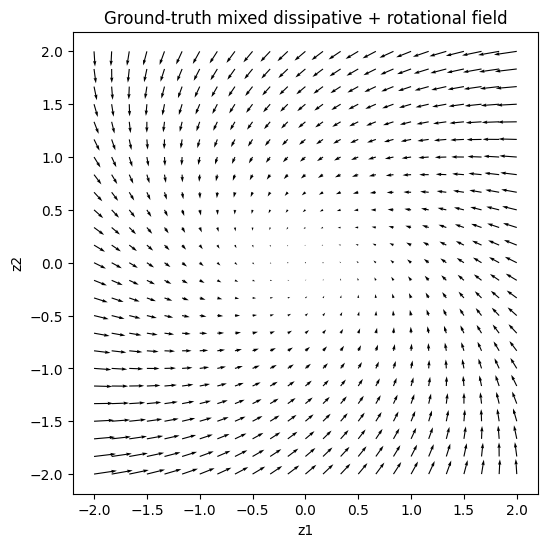

In [4]:

# Ground-truth vector field.
grid = torch.linspace(-2, 2, 25, device=DEVICE)
gx, gy = torch.meshgrid(grid, grid, indexing="xy")
zg = torch.stack([gx.reshape(-1), gy.reshape(-1)], dim=-1)

with torch.no_grad():
    fg = true_field(zg).cpu().numpy()
zg_np = zg.cpu().numpy()

plt.figure(figsize=(6,6))
plt.quiver(zg_np[:,0], zg_np[:,1], fg[:,0], fg[:,1])
plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Ground-truth mixed dissipative + rotational field")
plt.axis("equal")
plt.show()



## 3. Model classes

### Baseline A — plain vector field

\[
F_\theta(z)=\mathrm{MLP}_\theta(z).
\]

### Baseline B — dissipative-only

\[
F_\theta(z)=-M_\theta\nabla U_\theta(z).
\]

### Structured model

\[
F_\theta(z)
=
-M_\theta\nabla U_\theta(z)
+
A_\theta\nabla H_\theta(z).
\]

For Phase 11A, \(M_\theta\) and \(A_\theta\) are global learned matrices. This intentionally reduces identifiability problems before moving to state-dependent operators.

We parameterize

\[
M_\theta=LL^\top+\epsilon I
\]

and

\[
A_\theta=B-B^\top.
\]


In [5]:

class MLP(nn.Module):
    def __init__(self, din, dout, hidden=64, depth=2):
        super().__init__()
        layers = []
        d = din
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.Tanh()]
            d = hidden
        layers += [nn.Linear(d, dout)]
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

class ScalarPotential(nn.Module):
    def __init__(self, hidden=64, depth=2):
        super().__init__()
        self.net = MLP(2, 1, hidden=hidden, depth=depth)

    def forward(self, z):
        return self.net(z).squeeze(-1)

def grad_scalar(scalar_model, z, create_graph=True):
    z_req = z.requires_grad_(True)
    value = scalar_model(z_req).sum()
    grad = torch.autograd.grad(
        value,
        z_req,
        create_graph=create_graph,
        retain_graph=create_graph,
    )[0]
    return grad

class PlainField(nn.Module):
    def __init__(self):
        super().__init__()
        self.field = MLP(2, 2, hidden=96, depth=3)

    def forward(self, z):
        return self.field(z)

class PSDMatrix2D(nn.Module):
    def __init__(self):
        super().__init__()
        self.raw = nn.Parameter(torch.tensor([0.2, 0.0, 0.2]))

    def matrix(self):
        # Lower triangular L with positive diagonal.
        l11 = F.softplus(self.raw[0]) + 1e-3
        l21 = self.raw[1]
        l22 = F.softplus(self.raw[2]) + 1e-3
        L = torch.stack([
            torch.stack([l11, torch.zeros_like(l11)]),
            torch.stack([l21, l22]),
        ])
        return L @ L.T + 1e-4 * torch.eye(2, device=L.device)

class SkewMatrix2D(nn.Module):
    def __init__(self):
        super().__init__()
        self.a = nn.Parameter(torch.tensor(0.1))

    def matrix(self):
        zero = torch.zeros_like(self.a)
        return torch.stack([
            torch.stack([zero, -self.a]),
            torch.stack([self.a, zero]),
        ])

class DissipativeField(nn.Module):
    def __init__(self):
        super().__init__()
        self.U = ScalarPotential(hidden=64, depth=2)
        self.M = PSDMatrix2D()

    def components(self, z, create_graph=True):
        gu = grad_scalar(self.U, z, create_graph=create_graph)
        M = self.M.matrix()
        fd = -(gu @ M.T)
        return fd, gu, M

    def forward(self, z):
        fd, _, _ = self.components(z, create_graph=self.training)
        return fd

class StructuredField(nn.Module):
    def __init__(self):
        super().__init__()
        self.U = ScalarPotential(hidden=64, depth=2)
        self.H = ScalarPotential(hidden=64, depth=2)
        self.M = PSDMatrix2D()
        self.A = SkewMatrix2D()

    def components(self, z, create_graph=True):
        gu = grad_scalar(self.U, z, create_graph=create_graph)
        gh = grad_scalar(self.H, z, create_graph=create_graph)
        M = self.M.matrix()
        A = self.A.matrix()
        fd = -(gu @ M.T)
        fr = gh @ A.T
        return fd, fr, gu, gh, M, A

    def forward(self, z):
        fd, fr, *_ = self.components(z, create_graph=self.training)
        return fd + fr



## 4. Training

All models see the same \((z,\dot z)\) pairs and use the same drift-MSE objective.

The structured model is not given the ground-truth components during training.


In [6]:

@dataclass
class TrainConfig:
    epochs: int = 1200
    batch_size: int = 256
    lr: float = 2e-3
    weight_decay: float = 1e-6
    print_every: int = 200

CFG = TrainConfig()

def train_model(model, z, target, cfg=CFG):
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(
        model.parameters(),
        lr=cfg.lr,
        weight_decay=cfg.weight_decay,
    )
    history = []

    n = len(z)

    for epoch in range(1, cfg.epochs+1):
        idx = torch.randint(0, n, (cfg.batch_size,), device=DEVICE)
        zb = z[idx].clone()
        yb = target[idx]

        model.train()
        pred = model(zb)
        loss = F.mse_loss(pred, yb)

        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 10.0)
        opt.step()

        history.append(float(loss.detach().cpu()))

        if epoch % cfg.print_every == 0 or epoch == 1:
            print(
                f"{model.__class__.__name__}: "
                f"epoch={epoch:4d} loss={history[-1]:.6f}"
            )

    return model, history

plain = PlainField()
diss = DissipativeField()
structured = StructuredField()

plain, hist_plain = train_model(plain, z_train, f_train)
diss, hist_diss = train_model(diss, z_train, f_train)
structured, hist_struct = train_model(structured, z_train, f_train)


PlainField: epoch=   1 loss=5.208015
PlainField: epoch= 200 loss=0.002033
PlainField: epoch= 400 loss=0.000975
PlainField: epoch= 600 loss=0.000219
PlainField: epoch= 800 loss=0.000216
PlainField: epoch=1000 loss=0.000066
PlainField: epoch=1200 loss=0.000078
DissipativeField: epoch=   1 loss=5.261942
DissipativeField: epoch= 200 loss=1.320493
DissipativeField: epoch= 400 loss=0.963157
DissipativeField: epoch= 600 loss=0.831177
DissipativeField: epoch= 800 loss=0.787519
DissipativeField: epoch=1000 loss=0.727188
DissipativeField: epoch=1200 loss=0.653968
StructuredField: epoch=   1 loss=5.081745
StructuredField: epoch= 200 loss=0.010154
StructuredField: epoch= 400 loss=0.002245
StructuredField: epoch= 600 loss=0.000869
StructuredField: epoch= 800 loss=0.000526
StructuredField: epoch=1000 loss=0.000302
StructuredField: epoch=1200 loss=0.000169


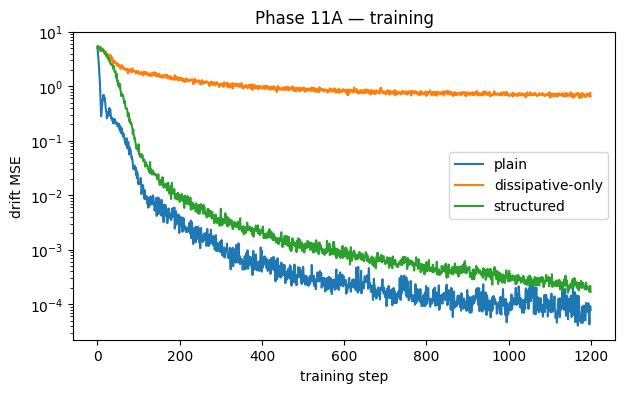

In [7]:

plt.figure(figsize=(7,4))
plt.plot(hist_plain, label="plain")
plt.plot(hist_diss, label="dissipative-only")
plt.plot(hist_struct, label="structured")
plt.yscale("log")
plt.xlabel("training step")
plt.ylabel("drift MSE")
plt.title("Phase 11A — training")
plt.legend()
plt.show()



## 5. Test metrics

We measure:

- total drift MSE;
- rollout error;
- cosine similarity to the true dissipative and rotational components;
- PSD eigenvalues of \(M_\theta\);
- skew-symmetry error of \(A_\theta\);
- dissipation condition

\[
\nabla U_\theta^\top F_{\rm diss}\le0;
\]

- rotational conservation condition

\[
\nabla H_\theta^\top F_{\rm rot}=0.
\]

Because \(U,H,M,A\) can rescale each other, **raw parameter recovery is not the main criterion**. Component-vector recovery is.


In [8]:

def cosine_mean(a, b, eps=1e-8):
    num = (a*b).sum(dim=-1)
    den = torch.norm(a, dim=-1) * torch.norm(b, dim=-1) + eps
    return float((num/den).mean().detach().cpu())

def mse(a,b):
    return float(F.mse_loss(a,b).detach().cpu())

def eval_plain(model):
    model.eval()
    with torch.no_grad():
        pred = model(z_test)
    return {"test_mse": mse(pred, f_test)}

def eval_diss(model):
    model.eval()
    z = z_test.clone().requires_grad_(True)
    fd, gu, M = model.components(z, create_graph=False)
    diss_rate = (gu * fd).sum(dim=-1)

    return {
        "test_mse": mse(fd, f_test),
        "M_min_eig": float(torch.linalg.eigvalsh(M).min().detach().cpu()),
        "dissipation_violation_fraction": float((diss_rate > 1e-6).float().mean().detach().cpu()),
        "mean_dU_dt_diss": float(diss_rate.mean().detach().cpu()),
    }

def eval_struct(model):
    model.eval()
    z = z_test.clone().requires_grad_(True)
    fd, fr, gu, gh, M, A = model.components(z, create_graph=False)
    pred = fd + fr

    diss_rate = (gu * fd).sum(dim=-1)
    h_rot_rate = (gh * fr).sum(dim=-1)

    return {
        "test_mse": mse(pred, f_test),
        "diss_component_mse": mse(fd, fd_test),
        "rot_component_mse": mse(fr, fr_test),
        "diss_component_cosine": cosine_mean(fd, fd_test),
        "rot_component_cosine": cosine_mean(fr, fr_test),
        "M_min_eig": float(torch.linalg.eigvalsh(M).min().detach().cpu()),
        "A_skew_error": float(torch.norm(A + A.T).detach().cpu()),
        "dissipation_violation_fraction": float((diss_rate > 1e-6).float().mean().detach().cpu()),
        "mean_dU_dt_diss": float(diss_rate.mean().detach().cpu()),
        "mean_abs_dH_dt_rot": float(h_rot_rate.abs().mean().detach().cpu()),
        "learned_A_scalar": float(model.A.a.detach().cpu()),
    }

metrics = pd.DataFrame(
    [
        {"model":"plain", **eval_plain(plain)},
        {"model":"dissipative_only", **eval_diss(diss)},
        {"model":"structured", **eval_struct(structured)},
    ]
)

display(metrics)
metrics.to_csv("phase11A_model_metrics.csv", index=False)


,model,test_mse,M_min_eig,dissipation_violation_fraction,mean_dU_dt_diss,diss_component_mse,rot_component_mse,diss_component_cosine,rot_component_cosine,A_skew_error,mean_abs_dH_dt_rot,learned_A_scalar
0,plain,0.000067,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,dissipative_only,0.698036,0.127926,0.0,-23.404089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,structured,0.000215,0.704490,0.0,-6.598678,0.30526,0.304564,0.941177,0.945331,0.0,8.825818e-08,0.369382



## 6. Visual decomposition

The structured model should reproduce not just the total vector field, but qualitatively separate inward/contractive and circulating motion.


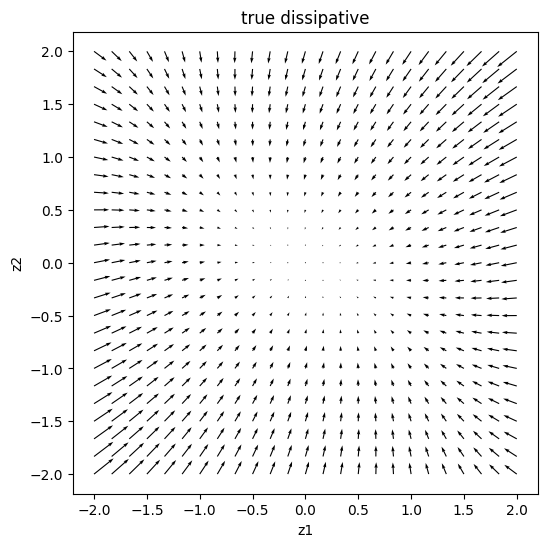

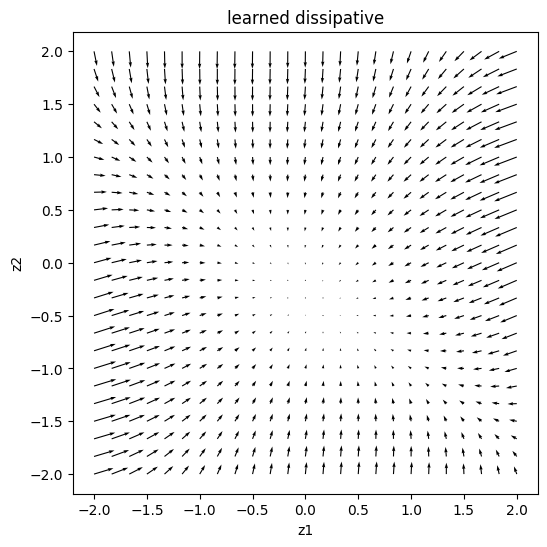

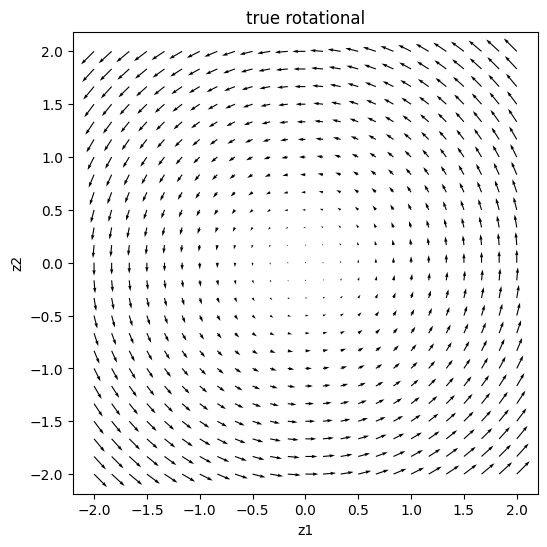

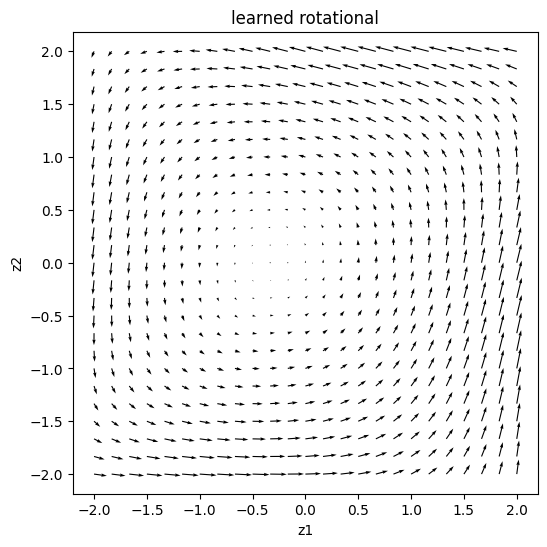

In [9]:

structured.eval()

zg_req = zg.clone().requires_grad_(True)
fd_pred, fr_pred, *_ = structured.components(zg_req, create_graph=False)

fd_true_g, fr_true_g = true_components(zg)

fig_data = [
    ("true dissipative", fd_true_g.detach().cpu().numpy()),
    ("learned dissipative", fd_pred.detach().cpu().numpy()),
    ("true rotational", fr_true_g.detach().cpu().numpy()),
    ("learned rotational", fr_pred.detach().cpu().numpy()),
]

for title, vec in fig_data:
    plt.figure(figsize=(6,6))
    plt.quiver(
        zg_np[:,0], zg_np[:,1],
        vec[:,0], vec[:,1],
    )
    plt.xlabel("z1")
    plt.ylabel("z2")
    plt.title(title)
    plt.axis("equal")
    plt.show()



## 7. Rollout test

A field can fit one-step velocities but still integrate badly.

We therefore compare multi-step trajectories using RK4.


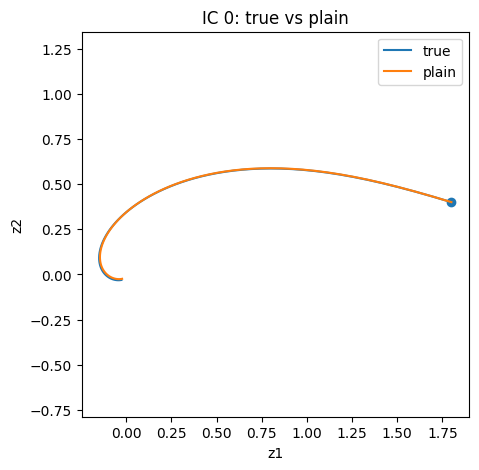

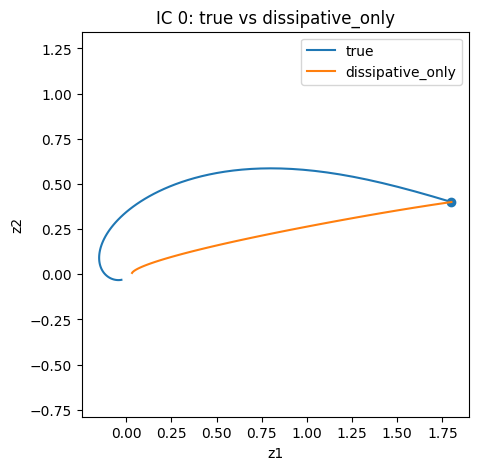

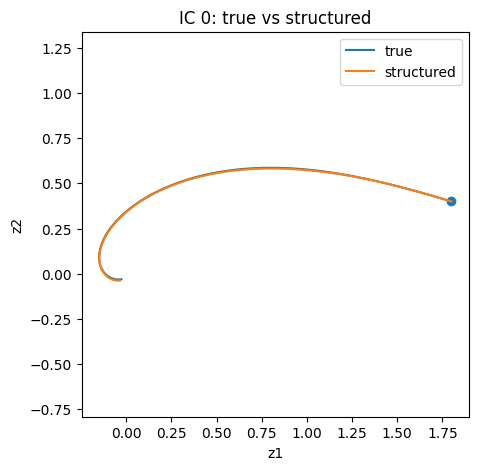

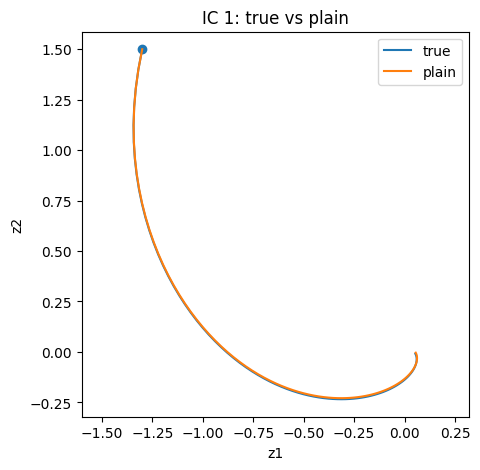

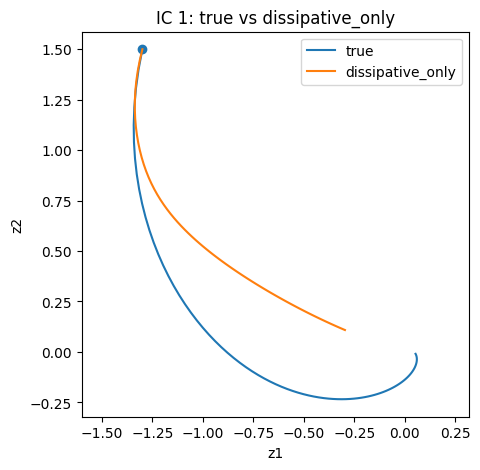

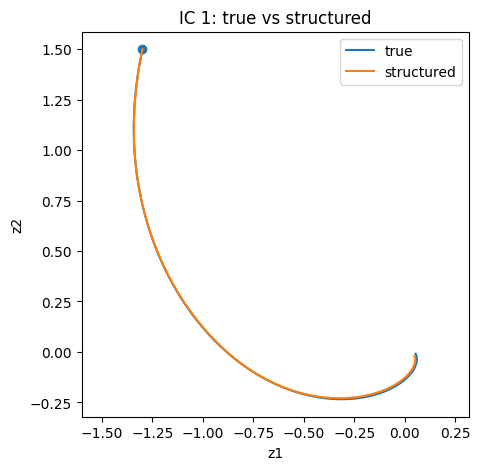

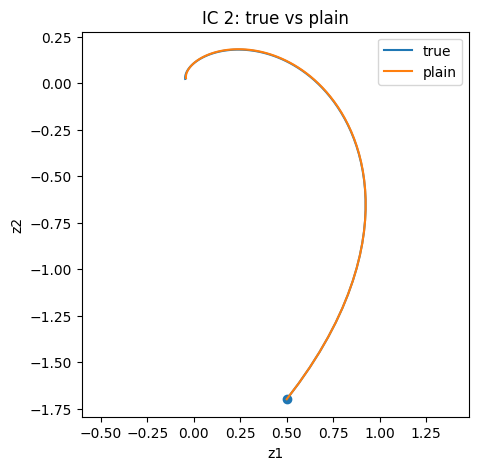

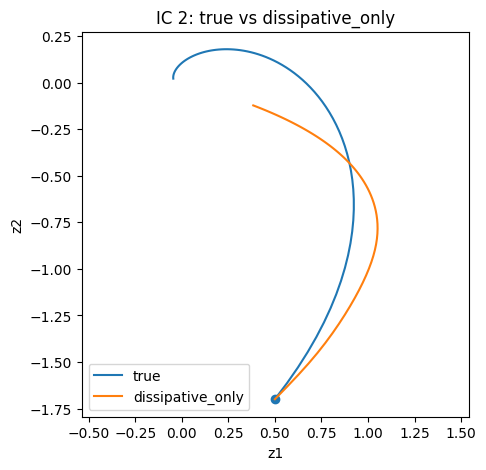

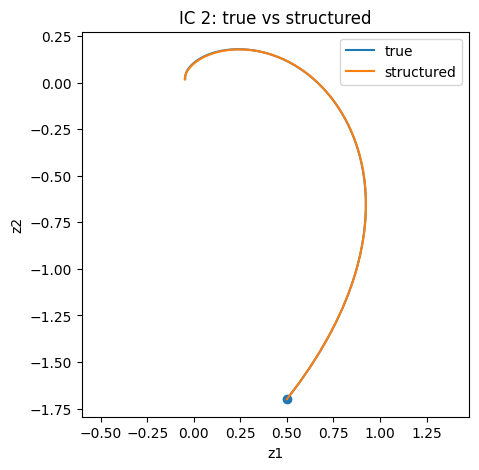

,initial_condition,model,rollout_rmse,final_state_error
0,0,plain,0.003429,0.007433
1,0,dissipative_only,0.193606,0.070235
2,0,structured,0.004340,0.010572
3,1,plain,0.003825,0.005946
4,1,dissipative_only,0.418645,0.369213
5,1,structured,0.006800,0.012423
6,2,plain,0.002139,0.005987
7,2,dissipative_only,0.402114,0.452837
8,2,structured,0.002551,0.005173


In [10]:

def field_no_graph(model, z):
    if isinstance(model, PlainField):
        return model(z)
    if isinstance(model, DissipativeField):
        fd, _, _ = model.components(z, create_graph=False)
        return fd
    if isinstance(model, StructuredField):
        fd, fr, *_ = model.components(z, create_graph=False)
        return fd + fr
    raise TypeError(type(model))

def rk4_step_field(field_fn, z, dt):
    k1 = field_fn(z)
    k2 = field_fn(z + 0.5*dt*k1)
    k3 = field_fn(z + 0.5*dt*k2)
    k4 = field_fn(z + dt*k3)
    return z + dt*(k1 + 2*k2 + 2*k3 + k4)/6.0

def rollout_true(z0, steps=100, dt=0.03):
    z = z0.clone()
    traj = [z.detach().clone()]
    for _ in range(steps):
        z = rk4_step_field(true_field, z, dt)
        traj.append(z.detach().clone())
    return torch.stack(traj)

def rollout_model(model, z0, steps=100, dt=0.03):
    model.eval()
    z = z0.clone()
    traj = [z.detach().clone()]
    for _ in range(steps):
        # Gradient-based models need local autograd enabled at every step.
        if isinstance(model, PlainField):
            with torch.no_grad():
                z = rk4_step_field(lambda x: model(x), z, dt)
        else:
            z = z.detach().requires_grad_(True)
            z = rk4_step_field(lambda x: field_no_graph(model, x), z, dt)
        traj.append(z.detach().clone())
    return torch.stack(traj)

z0s = torch.tensor(
    [[1.8, 0.4],
     [-1.3, 1.5],
     [0.5, -1.7]],
    dtype=DTYPE,
    device=DEVICE,
)

rollout_rows = []

for j, z0 in enumerate(z0s):
    true_tr = rollout_true(z0)

    for name, model in [
        ("plain", plain),
        ("dissipative_only", diss),
        ("structured", structured),
    ]:
        pred_tr = rollout_model(model, z0)
        rmse = torch.sqrt(torch.mean((pred_tr-true_tr)**2))
        final_err = torch.norm(pred_tr[-1]-true_tr[-1])

        rollout_rows.append({
            "initial_condition": j,
            "model": name,
            "rollout_rmse": float(rmse.cpu()),
            "final_state_error": float(final_err.cpu()),
        })

        true_np = true_tr.cpu().numpy()
        pred_np = pred_tr.cpu().numpy()

        plt.figure(figsize=(5,5))
        plt.plot(true_np[:,0], true_np[:,1], label="true")
        plt.plot(pred_np[:,0], pred_np[:,1], label=name)
        plt.scatter([true_np[0,0]], [true_np[0,1]], marker="o")
        plt.xlabel("z1")
        plt.ylabel("z2")
        plt.title(f"IC {j}: true vs {name}")
        plt.axis("equal")
        plt.legend()
        plt.show()

rollout_df = pd.DataFrame(rollout_rows)
display(rollout_df)
rollout_df.to_csv("phase11A_rollout_metrics.csv", index=False)



# Phase 11A decision gate

The structured decomposition is worth extending to stochastic dynamics only if it does more than fit the total vector field.

Look for all of the following:

1. structured total-field MSE competitive with the plain MLP;
2. structured model substantially better than dissipative-only on mixed rotational dynamics;
3. high cosine similarity for both learned components;
4. \(M_\theta\) remains PSD;
5. \(A_\theta\) remains skew-symmetric;
6. negligible violations of
   \[
   \nabla U_\theta^\top F_{\rm diss}\le0;
   \]
7. near-zero
   \[
   \nabla H_\theta^\top F_{\rm rot};
   \]
8. structured rollouts preserve the qualitative spiral/relaxation geometry.

If Phase 11A passes, Phase 11B should add

\[
G_\theta(z,t)dW_t
\]

and test whether drift and diffusion can be learned separately from stochastic trajectories.
